# Polarization: Jones and Mueller calculus

`pyoptics.polarization.jones` describes fully polarized light with complex
2-vectors $[E_x, E_y]$ and 2×2 matrices, `pyoptics.polarization.mueller` arbitrary
(including partially polarized) light with real Stokes vectors
$S = (S_0, S_1, S_2, S_3)$ and 4×4 matrices. This notebook draws polarization
ellipses, shows Malus' law and the three-polarizer "paradox", follows wave plates
on the Poincaré sphere and builds a Fresnel rhomb.

**Convention:** $\exp(i(kz - \omega t))$. The Jones vector $[1, i]/\sqrt{2}$ then
describes the real field $(\cos\omega t, \sin\omega t)$: it rotates from $x$ to
$y$, i.e. counter-clockwise for an observer looking towards the oncoming wave.
`pyoptics` calls this `J_RHCP` with $S_3 = +1$ (right-handed in the IEEE
convention, "left" in the traditional optics naming).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pyoptics.polarization import jones as J
from pyoptics.polarization import mueller as M
from pyoptics import interfaces as itf

plt.rcParams.update({"figure.dpi": 100, "font.size": 11})
deg = np.pi/180

def draw_ellipse(ax, E, color="C0", title=None):
    """Path of the real field Re(E exp(-i omega t)) in the xy plane, looking towards the oncoming wave."""
    wt = np.linspace(0, 2*np.pi, 200)
    Ex = np.real(E[0]*np.exp(-1j*wt)); Ey = np.real(E[1]*np.exp(-1j*wt))
    ax.plot(Ex, Ey, color=color, lw=2)
    # arrow in the direction of increasing time:
    i0, i1 = 10, 18
    ax.annotate("", xy=(Ex[i1], Ey[i1]), xytext=(Ex[i0], Ey[i0]),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=2, mutation_scale=18))
    ax.plot(Ex[0], Ey[0], "o", color=color, ms=4)
    ax.axhline(0, color="0.8", lw=0.5); ax.axvline(0, color="0.8", lw=0.5)
    ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=10)

## 1. Polarization states and Stokes parameters

The ellipse is the path of the field tip during one period (dot: $t = 0$, arrow:
direction of motion). Below each, the Stokes vector from `stokes_from_complex_E()`:
$S_1$ measures horizontal vs. vertical, $S_2$ $+45°$ vs. $-45°$, $S_3$ the
handedness.

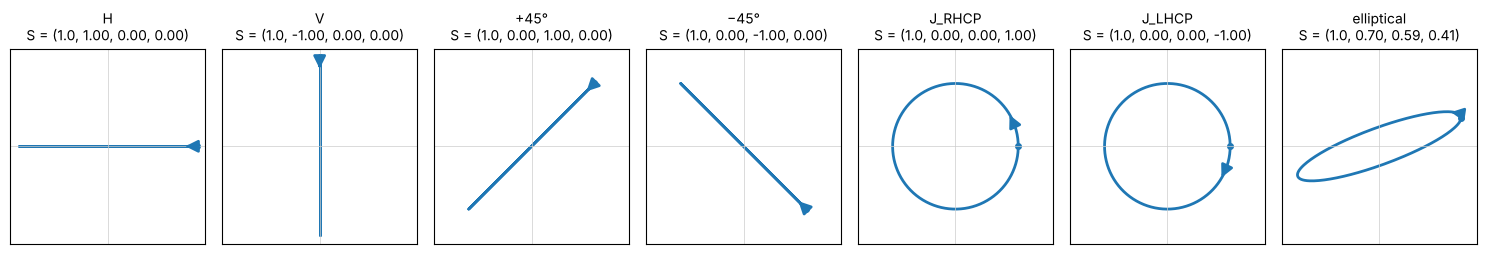

In [2]:
states = {"H": J.J_H, "V": J.J_V, "+45°": J.J_Lp45, "−45°": J.J_Lm45,
          "J_RHCP": J.J_RHCP, "J_LHCP": J.J_LHCP,
          "elliptical": np.array([np.cos(0.4), np.sin(0.4)*np.exp(0.6j)])}
fig, axes = plt.subplots(1, len(states), figsize=(15, 2.9))
for ax, (name, E) in zip(axes, states.items()):
    S = M.stokes_from_complex_E(E)
    draw_ellipse(ax, E, title=f"{name}\nS = ({S[0]:.1f}, {S[1]:.2f}, {S[2]:.2f}, {S[3]:.2f})")
fig.tight_layout()

## 2. Malus' law and three polarizers

A polarizer at the angle $\varphi$ to the polarization direction transmits
$I = I_0\cos^2\varphi$. Two crossed polarizers block everything. Put a third one at
$45°$ *in between*, and a quarter gets through again. With $N$ polarizers in equal
angular steps from $0°$ to $90°$, the transmission is $\cos^{2N}(\pi/2N)$ and tends
to one for $N \to \infty$: the polarization is "carried along" without loss.

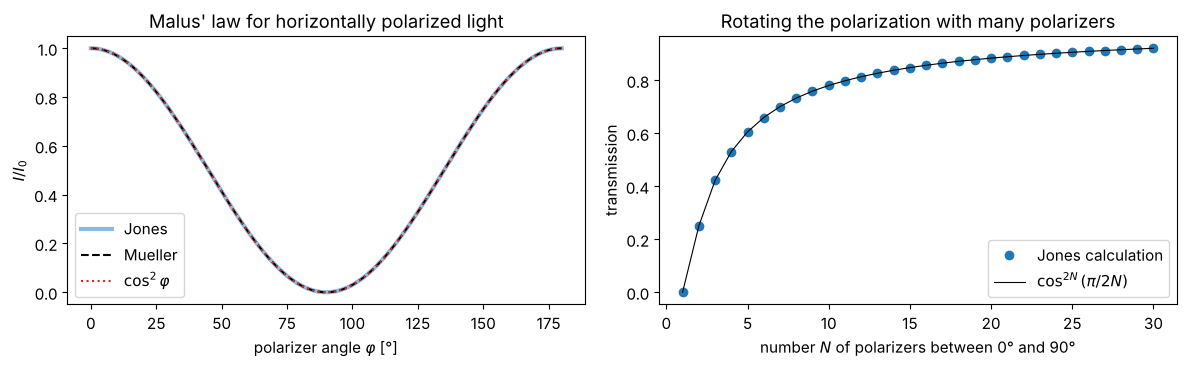

In [3]:
phi = np.linspace(0, np.pi, 181)
I_jones = [np.sum(np.abs(J.J_rot_polarizer(p) @ J.J_H)**2) for p in phi]
I_mueller = [(M.M_linear_polarizer(p) @ M.S_LHP)[0] for p in phi]

def chain_transmission(N):
    E = J.J_H.astype(complex)
    for p in np.linspace(0, np.pi/2, N + 1)[1:]:
        E = J.J_rot_polarizer(p) @ E
    return np.sum(np.abs(E)**2)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(phi/deg, I_jones, lw=3, alpha=0.5, label="Jones")
axes[0].plot(phi/deg, I_mueller, "k--", label="Mueller")
axes[0].plot(phi/deg, np.cos(phi)**2, ":", color="C3", label="$\\cos^2\\varphi$")
axes[0].set_xlabel("polarizer angle $\\varphi$ [°]"); axes[0].set_ylabel("$I/I_0$"); axes[0].legend()
axes[0].set_title("Malus' law for horizontally polarized light")
Ns = np.arange(1, 31)
axes[1].plot(Ns, [chain_transmission(N) for N in Ns], "o", label="Jones calculation")
axes[1].plot(Ns, np.cos(np.pi/(2*Ns))**(2*Ns), "k-", lw=0.8, label="$\\cos^{2N}(\\pi/2N)$")
axes[1].set_xlabel("number $N$ of polarizers between 0° and 90°"); axes[1].set_ylabel("transmission")
axes[1].set_title("Rotating the polarization with many polarizers"); axes[1].legend()
fig.tight_layout()

## 3. Wave plates and the Poincaré sphere

A wave plate retards the component along its slow axis by $\delta$. The
half-wave plate ($\delta = \pi$) at the angle $\theta$ rotates linear polarization
by $2\theta$. The quarter-wave plate ($\delta = \pi/2$) at $45°$ turns linear into
circular polarization.

On the **Poincaré sphere** (point $(S_1, S_2, S_3)/S_0$) every wave plate acts as
a rotation about its fast axis (a point on the equator) by the angle $\delta$.
Rotating a quarter-wave plate in front of horizontally polarized light, the output
state traces a figure eight.

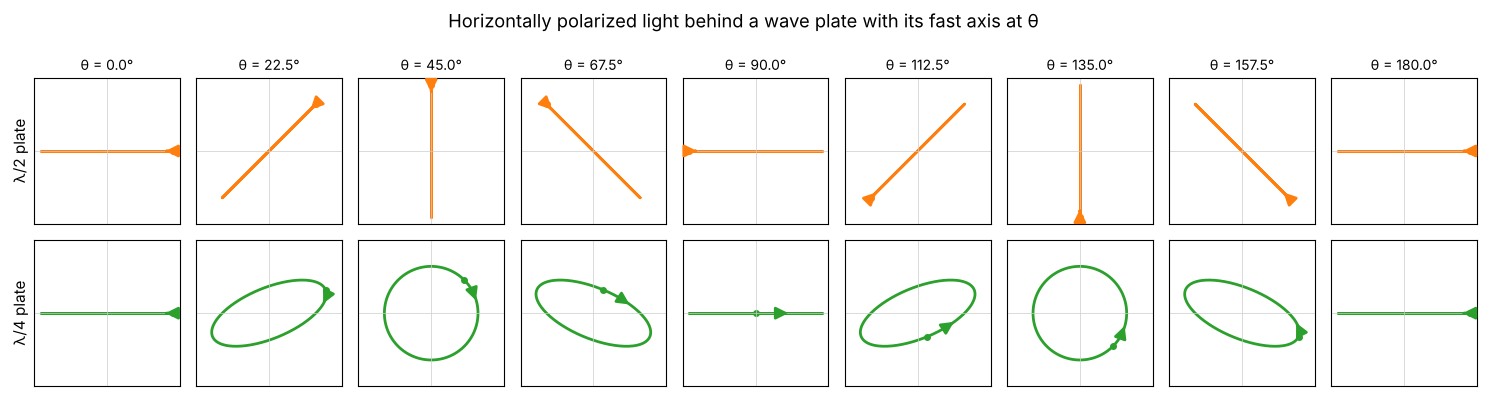

In [4]:
thetas = np.arange(0, 181, 22.5)*deg
fig, axes = plt.subplots(2, len(thetas), figsize=(15, 4.2))
for i, th in enumerate(thetas):
    draw_ellipse(axes[0, i], J.J_WP(np.pi, th) @ J.J_H, color="C1", title=f"θ = {th/deg:.1f}°")
    draw_ellipse(axes[1, i], J.J_WP(np.pi/2, th) @ J.J_H, color="C2")
axes[0, 0].set_ylabel("λ/2 plate"); axes[1, 0].set_ylabel("λ/4 plate")
fig.suptitle("Horizontally polarized light behind a wave plate with its fast axis at θ")
fig.tight_layout()

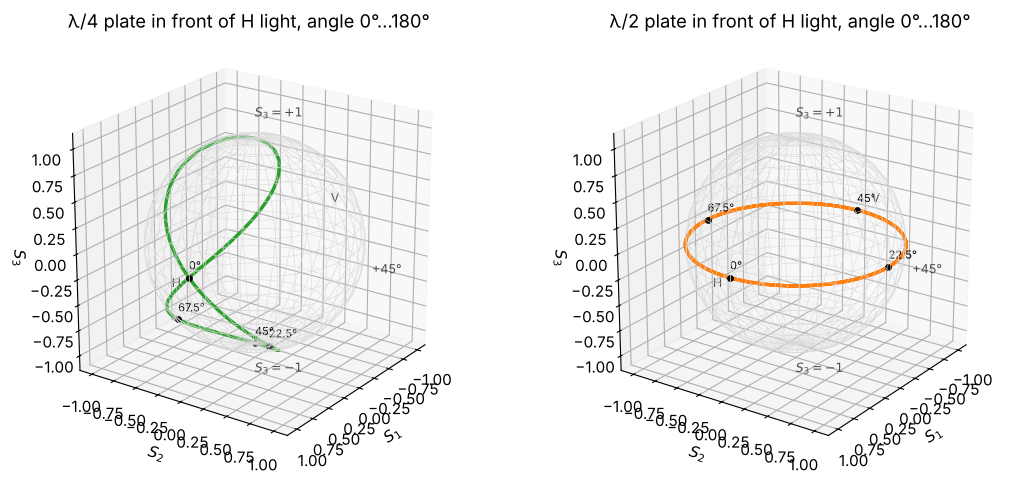

In [5]:
fig = plt.figure(figsize=(11, 5))
for j, (delta, name, c) in enumerate(((np.pi/2, "λ/4 plate", "C2"), (np.pi, "λ/2 plate", "C1"))):
    ax = fig.add_subplot(1, 2, j + 1, projection="3d")
    u, v = np.mgrid[0:2*np.pi:40j, 0:np.pi:20j]
    ax.plot_wireframe(np.cos(u)*np.sin(v), np.sin(u)*np.sin(v), np.cos(v), color="0.85", lw=0.4)
    th = np.linspace(0, np.pi, 400)
    S = np.array([M.M_retarder(t, delta) @ M.S_LHP for t in th])
    ax.plot(S[:, 1], S[:, 2], S[:, 3], color=c, lw=2.5)
    for t in (0, 22.5, 45, 67.5):
        s = M.M_retarder(t*deg, delta) @ M.S_LHP
        ax.scatter(s[1], s[2], s[3], color="k", s=15)
        ax.text(s[1], s[2], s[3] + 0.08, f"{t}°", fontsize=8)
    for (x, y, z, lab) in ((1.25, 0, 0, "H"), (-1.25, 0, 0, "V"), (0, 1.25, 0, "+45°"), (0, 0, 1.2, "$S_3=+1$"), (0, 0, -1.3, "$S_3=-1$")):
        ax.text(x, y, z, lab, fontsize=9, color="0.3")
    ax.set_xlabel("$S_1$"); ax.set_ylabel("$S_2$"); ax.set_zlabel("$S_3$")
    ax.set_box_aspect((1, 1, 1)); ax.view_init(elev=22, azim=35)
    ax.set_title(f"{name} in front of H light, angle 0°…180°")
fig.tight_layout()

The half-wave plate takes the state around the equator twice (linear
polarization, rotation angle $2\theta$); the quarter-wave plate reaches the poles
(circular) at $\theta = \pm 45°$.

## 4. Jones and Mueller are consistent, but Mueller can do more

`M_from_jones()` converts any Jones matrix into a Mueller matrix. For the elements
in `mueller.py` this gives exactly the same matrices:

polarizer 30°        max|M - M_from_jones(J)| = 1.1e-16
λ/4 plate 20°        max|M - M_from_jones(J)| = 2.2e-16
retarder δ=1, 70°    max|M - M_from_jones(J)| = 2.2e-16


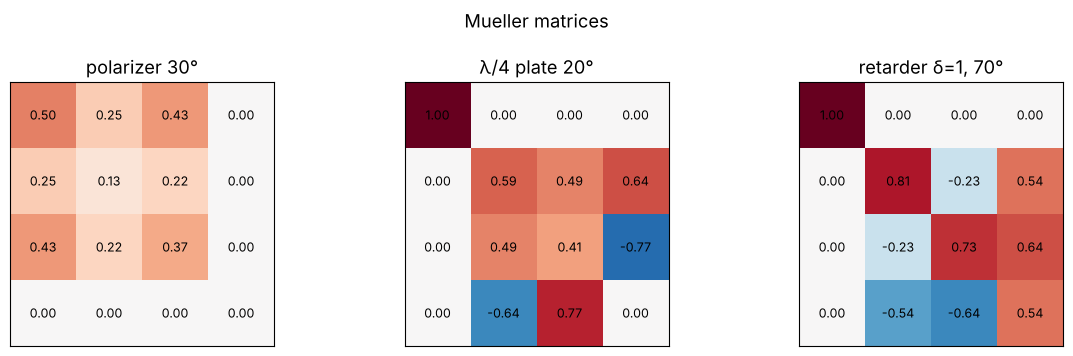

In [6]:
checks = {
    "polarizer 30°": (M.M_linear_polarizer(30*deg), J.J_rot_polarizer(30*deg)),
    "λ/4 plate 20°": (M.M_retarder(20*deg, np.pi/2), J.J_WP(np.pi/2, 20*deg)),
    "retarder δ=1, 70°": (M.M_retarder(70*deg, 1.0), J.J_WP(1.0, 70*deg)),
}
for name, (Mm, Jm) in checks.items():
    print(f"{name:20s} max|M - M_from_jones(J)| = {np.max(np.abs(Mm - M.M_from_jones(Jm))):.1e}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (name, (Mm, _)) in zip(axes, checks.items()):
    ax.imshow(Mm, cmap="RdBu_r", vmin=-1, vmax=1)
    for (i, j), val in np.ndenumerate(Mm):
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(name)
fig.suptitle("Mueller matrices")
fig.tight_layout()

What Jones cannot do: **depolarization**. A bundle whose partial beams experience
different retardations (e.g. from a rough or stressed plate) adds up
incoherently. The Mueller matrix is then the average of the individual Mueller
matrices, and the degree of polarization
$\mathrm{DOP} = \sqrt{S_1^2 + S_2^2 + S_3^2}/S_0$ drops below one.

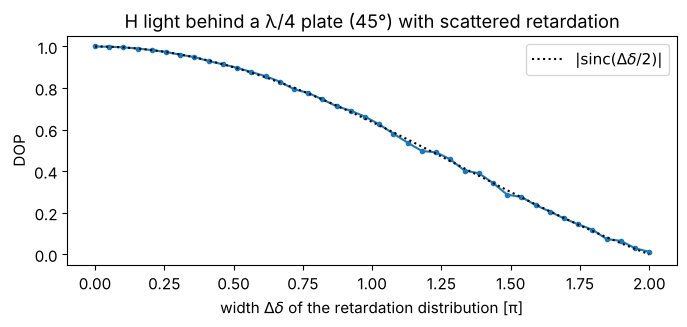

In [7]:
rng = np.random.default_rng(1)
spreads = np.linspace(0, 2*np.pi, 40)
dop = []
for spread in spreads:
    deltas = np.pi/2 + spread*(rng.random(2000) - 0.5)
    M_avg = np.mean([M.M_retarder(45*deg, d) for d in deltas], axis=0)
    dop.append(M.stokes_DOP(M_avg @ M.S_LHP))
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(spreads/np.pi, dop, "o-", ms=3)
ax.plot(spreads/np.pi, np.abs(np.sinc(spreads/(2*np.pi))), "k:", label="$|\\mathrm{sinc}(\\Delta\\delta/2)|$")
ax.set_xlabel("width $\\Delta\\delta$ of the retardation distribution [π]"); ax.set_ylabel("DOP")
ax.set_title("H light behind a λ/4 plate (45°) with scattered retardation"); ax.legend()
fig.tight_layout()

## 5. Reflection at glass polarizes

Unpolarized light ($S = (1, 0, 0, 0)$) is partially polarized on reflection at
glass, because $R_s \neq R_p$. `M_reflection_dielectric(r_s, r_p)` builds the
Mueller matrix from the Fresnel coefficients. At the Brewster angle, the reflected
light is fully s polarized. This is what polarizing sunglasses use to suppress
reflections from water and roads.

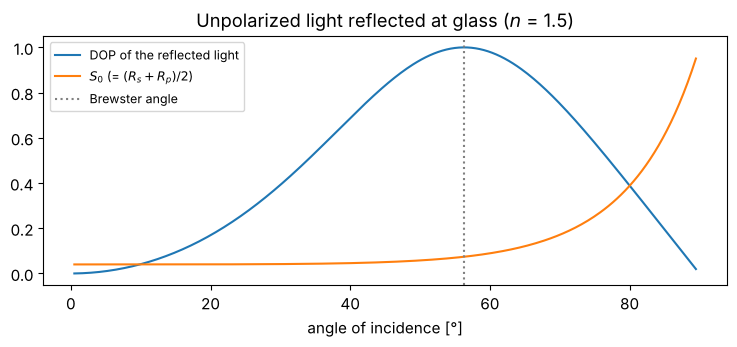

In [8]:
theta = np.linspace(0.5, 89.5, 300)*deg
n_glass = 1.5
S_refl = np.array([M.M_reflection_dielectric(itf.r_s(t, 1.0, n_glass), itf.r_p(t, 1.0, n_glass)) @ M.S_unpol
                   for t in theta])
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(theta/deg, [M.stokes_DOP(S) for S in S_refl], label="DOP of the reflected light")
ax.plot(theta/deg, S_refl[:, 0], label="$S_0$ (= $(R_s + R_p)/2$)")
ax.axvline(itf.brewster_angle(1.0, n_glass)/deg, color="0.5", ls=":", label="Brewster angle")
ax.set_xlabel("angle of incidence [°]"); ax.legend(fontsize=9)
ax.set_title("Unpolarized light reflected at glass ($n$ = 1.5)")
fig.tight_layout()

## 6. The Fresnel rhomb: a quarter-wave plate from total internal reflection

Under total internal reflection, the s and p components pick up different phases
(notebook 03). `M_TIR(phi, n)` is the Mueller matrix of a retarder with

$$\delta(\varphi) = 2\arctan\frac{\cos\varphi\sqrt{n^2\sin^2\varphi - 1}}{n\sin^2\varphi}.$$

For crown glass ($n = 1.51$) the maximum is just above $45°$. Fresnel chose an angle
with $\delta = 45°$ and let the light be totally reflected **twice** inside the
rhomb: $90°$ in total, i.e. a quarter-wave plate that (unlike birefringent plates)
hardly depends on the wavelength.

The comparison with $\arg r_s - \arg r_p$ from `interfaces` shows that both modules
use the same convention.

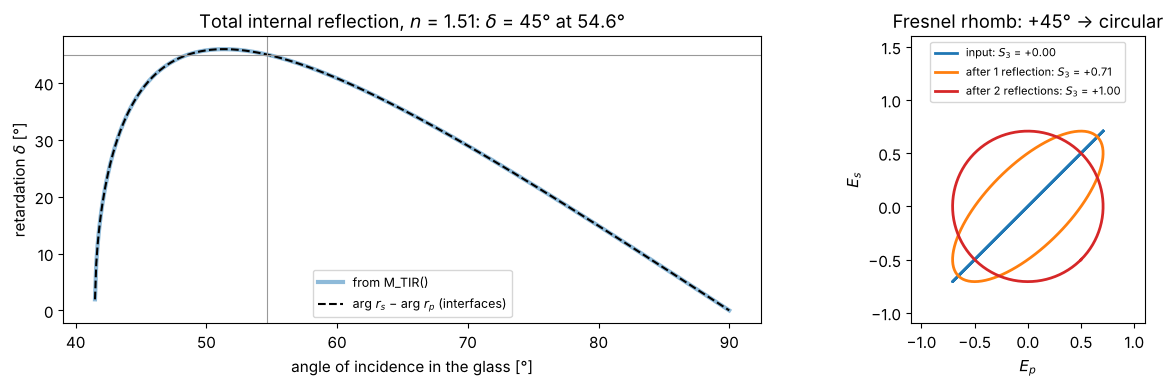

In [9]:
n_rhomb = 1.51
phi = np.linspace(np.arcsin(1/n_rhomb) + 1e-4, np.pi/2 - 1e-4, 500)
delta_M = np.array([np.arctan2(M.M_TIR(p, n_rhomb)[3, 2], M.M_TIR(p, n_rhomb)[2, 2]) for p in phi])
delta_F = np.angle(itf.r_s(phi, n_rhomb, 1.0)) - np.angle(itf.r_p(phi, n_rhomb, 1.0))
delta_F = np.mod(delta_F + np.pi, 2*np.pi) - np.pi

# angle with delta = 45° (the larger of the two solutions, as with Fresnel):
i_max = np.argmax(delta_M)
phi_45 = phi[i_max:][np.argmin(np.abs(delta_M[i_max:] - np.pi/4))]

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1.4, 1]})
axes[0].plot(phi/deg, delta_M/deg, lw=3, alpha=0.5, label="from M_TIR()")
axes[0].plot(phi/deg, delta_F/deg, "k--", label="arg $r_s$ − arg $r_p$ (interfaces)")
axes[0].axhline(45, color="0.6", lw=0.8); axes[0].axvline(phi_45/deg, color="0.6", lw=0.8)
axes[0].set_xlabel("angle of incidence in the glass [°]"); axes[0].set_ylabel("retardation $\\delta$ [°]")
axes[0].set_title(f"Total internal reflection, $n$ = {n_rhomb}: $\\delta$ = 45° at {phi_45/deg:.1f}°"); axes[0].legend(fontsize=9)

# light at 45° to the plane of incidence (p = x, s = y): two total internal reflections
S_in = M.S_Lp45P
S_one = M.M_TIR(phi_45, n_rhomb) @ S_in
S_two = M.M_TIR(phi_45, n_rhomb) @ S_one
for S, name, c in ((S_in, "input", "C0"), (S_one, "after 1 reflection", "C1"), (S_two, "after 2 reflections", "C3")):
    # Stokes -> a matching Jones vector for drawing:
    psi = 0.5*np.arctan2(S[2], S[1]); chi = 0.5*np.arcsin(np.clip(S[3]/S[0], -1, 1))
    E = np.array([np.cos(psi)*np.cos(chi) - 1j*np.sin(psi)*np.sin(chi),
                  np.sin(psi)*np.cos(chi) + 1j*np.cos(psi)*np.sin(chi)])
    wt = np.linspace(0, 2*np.pi, 200)
    axes[1].plot(np.real(E[0]*np.exp(-1j*wt)), np.real(E[1]*np.exp(-1j*wt)), color=c, lw=2,
                 label=f"{name}: $S_3$ = {S[3]:+.2f}")
axes[1].set_aspect("equal"); axes[1].set_xlim(-1.1, 1.1); axes[1].set_ylim(-1.1, 1.6)
axes[1].set_xlabel("$E_p$"); axes[1].set_ylabel("$E_s$"); axes[1].legend(fontsize=8, loc="upper center")
axes[1].set_title("Fresnel rhomb: +45° → circular")
fig.tight_layout()

## 7. Reflection at a metal

`M_reflection_metal()` computes the Mueller matrix for a metal with a complex
refractive index. Light linearly polarized at $45°$ becomes elliptical; at an angle
of incidence close to the principal angle (notebook 03) the retardation is $90°$
and the ellipse stands upright.

That $+45°$ apparently turns into $-45°$ at $\theta = 0$ is not a physical effect
but the usual mirroring: the coordinates $(p, s)$ refer to the reflected beam,
which travels in the opposite direction (this is why $r_p = -r_s$ at normal
incidence in the Hecht convention).

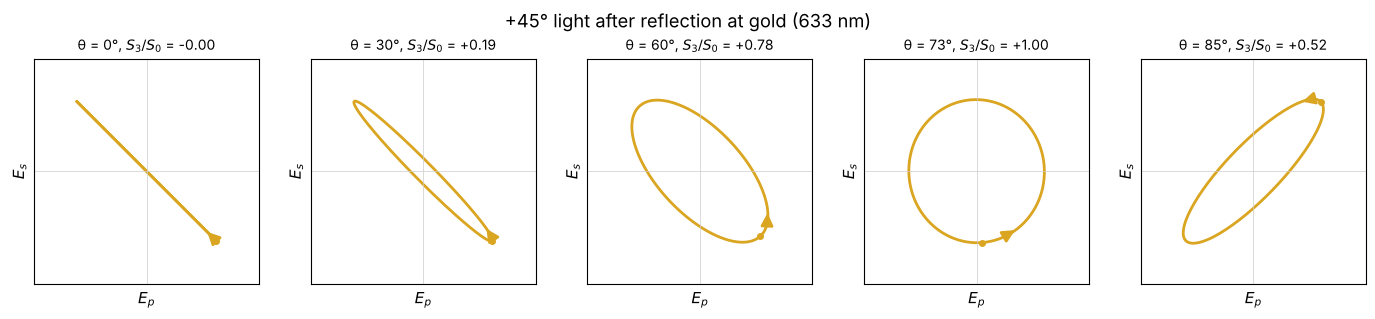

In [10]:
n_Au = 0.18 + 3.0j
angles = (0, 30, 60, 73, 85)
fig, axes = plt.subplots(1, len(angles), figsize=(14, 3))
for ax, a in zip(axes, angles):
    S = M.M_reflection_metal(a*deg, n_Au) @ M.S_Lp45P
    psi = 0.5*np.arctan2(S[2], S[1]); chi = 0.5*np.arcsin(np.clip(S[3]/S[0], -1, 1))
    E = np.sqrt(S[0])*np.array([np.cos(psi)*np.cos(chi) - 1j*np.sin(psi)*np.sin(chi),
                                np.sin(psi)*np.cos(chi) + 1j*np.cos(psi)*np.sin(chi)])
    draw_ellipse(ax, E, color="goldenrod", title=f"θ = {a}°, $S_3/S_0$ = {S[3]/S[0]:+.2f}")
    ax.set_xlabel("$E_p$"); ax.set_ylabel("$E_s$")
fig.suptitle("+45° light after reflection at gold (633 nm)")
fig.tight_layout()